# **Project: Amazon Product Recommendation System**

# **Marks: 40**


Welcome to the project on Recommendation Systems. We will work with the Amazon product reviews dataset for this project. The dataset contains ratings of different electronic products. It does not include information about the products or reviews to avoid bias while building the model.

--------------
## **Context:**
--------------

Today, information is growing exponentially with volume, velocity and variety throughout the globe. This has lead to information overload, and too many choices for the consumer of any business. It represents a real dilemma for these consumers and they often turn to denial. Recommender Systems are one of the best tools that help recommending products to consumers while they are browsing online. Providing personalized recommendations which is most relevant for the user is what's most likely to keep them engaged and help business.

E-commerce websites like Amazon, Walmart, Target and Etsy use different recommendation models to provide personalized suggestions to different users. These companies spend millions of dollars to come up with algorithmic techniques that can provide personalized recommendations to their users.

Amazon, for example, is well-known for its accurate selection of recommendations in its online site. Amazon's recommendation system is capable of intelligently analyzing and predicting customers' shopping preferences in order to offer them a list of recommended products. Amazon's recommendation algorithm is therefore a key element in using AI to improve the personalization of its website. For example, one of the baseline recommendation models that Amazon uses is item-to-item collaborative filtering, which scales to massive data sets and produces high-quality recommendations in real-time.

----------------
## **Objective:**
----------------

You are a Data Science Manager at Amazon, and have been given the task of building a recommendation system to recommend products to customers based on their previous ratings for other products. You have a collection of labeled data of Amazon reviews of products. The goal is to extract meaningful insights from the data and build a recommendation system that helps in recommending products to online consumers.

-----------------------------
## **Dataset:**
-----------------------------

The Amazon dataset contains the following attributes:

- **userId:** Every user identified with a unique id
- **productId:** Every product identified with a unique id
- **Rating:** The rating of the corresponding product by the corresponding user
- **timestamp:** Time of the rating. We **will not use this column** to solve the current problem

**Note:** The code has some user defined functions that will be usefull while making recommendations and measure model performance, you can use these functions or can create your own functions.

Sometimes, the installation of the surprise library, which is used to build recommendation systems, faces issues in Jupyter. To avoid any issues, it is advised to use **Google Colab** for this project.

Let's start by mounting the Google drive on Colab.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Installing surprise library**

In [2]:
# Installing the correct library
!pip install surprise

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.4/154.4 kB 3.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-surprise: filename=scikit_surprise-1.1.4-cp311-cp311-linux_x86_64.whl size=2505174 sha256=839a68c9c9768f1f8bb4d651497aa94c60945de68c1345f1ae4125879ec7e890
  Stored in directory: /root/.cache/pip/wheels/2a/8f/6e/7e2899163e2d85d8266daab4aa1cdabec7a6c56f83c015b5af
Successfully built scikit-surprise


## **Importing the necessary libraries and overview of the dataset**

In [3]:
# Libraries for math and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Additional
from collections import defaultdict

# Not show warnings
import warnings
warnings.filterwarnings('ignore')

### **Loading the data**
- Import the Dataset
- Add column names ['user_id', 'prod_id', 'rating', 'timestamp']
- Drop the column timestamp
- Copy the data to another DataFrame called **df**

In [4]:
# Reading the dataset
ratings = pd.read_csv("/content/drive/MyDrive/Week11/Project_Assessment/ratings_Electronics.csv")

In [5]:
# Check how the data looks like
ratings.head()

,AKM1MP6P0OYPR,0132793040,5.0,1365811200
0,A2CX7LUOHB2NDG,0321732944,5.0,1341100800
1,A2NWSAGRHCP8N5,0439886341,1.0,1367193600
2,A2WNBOD3WNDNKT,0439886341,3.0,1374451200
3,A1GI0U4ZRJA8WN,0439886341,1.0,1334707200
4,A1QGNMC6O1VW39,0511189877,5.0,1397433600


We need to add the column names as indicated above.


In [6]:
ratings.columns = ['user_id', 'prod_id', 'rating', 'timestamp']
ratings.head()

,user_id,prod_id,rating,timestamp
0,A2CX7LUOHB2NDG,0321732944,5.0,1341100800
1,A2NWSAGRHCP8N5,0439886341,1.0,1367193600
2,A2WNBOD3WNDNKT,0439886341,3.0,1374451200
3,A1GI0U4ZRJA8WN,0439886341,1.0,1334707200
4,A1QGNMC6O1VW39,0511189877,5.0,1397433600


We drop the timestamps, as requested. It is also logical, as it will not really contribute to the excercise we want to complete now.

In [7]:
ratings.drop(columns=['timestamp'], inplace = True)
ratings.head()

,user_id,prod_id,rating
0,A2CX7LUOHB2NDG,0321732944,5.0
1,A2NWSAGRHCP8N5,0439886341,1.0
2,A2WNBOD3WNDNKT,0439886341,3.0
3,A1GI0U4ZRJA8WN,0439886341,1.0
4,A1QGNMC6O1VW39,0511189877,5.0


We create a copy for ease of working.


In [8]:
df = ratings.copy()
df.head()

,user_id,prod_id,rating
0,A2CX7LUOHB2NDG,0321732944,5.0
1,A2NWSAGRHCP8N5,0439886341,1.0
2,A2WNBOD3WNDNKT,0439886341,3.0
3,A1GI0U4ZRJA8WN,0439886341,1.0
4,A1QGNMC6O1VW39,0511189877,5.0


**As this dataset is very large and has 7,824,482 observations, it is not computationally possible to build a model using this. Moreover, many users have only rated a few products and also some products are rated by very few users. Hence, we can reduce the dataset by considering certain logical assumptions.**

Here, we will be taking users who have given at least 50 ratings, and the products that have at least 5 ratings, as when we shop online we prefer to have some number of ratings of a product.

In [9]:
# Get the column containing the users
users = df.user_id

# Create a dictionary from users to their number of ratings
ratings_count = dict()

for user in users:

    # If we already have the user, just add 1 to their rating count
    if user in ratings_count:
        ratings_count[user] += 1

    # Otherwise, set their rating count to 1
    else:
        ratings_count[user] = 1

In [10]:
# We want our users to have at least 50 ratings to be considered
RATINGS_CUTOFF = 50

remove_users = []

for user, num_ratings in ratings_count.items():
    if num_ratings < RATINGS_CUTOFF:
        remove_users.append(user)

df = df.loc[ ~ df.user_id.isin(remove_users)]

In [11]:
# Get the column containing the products
prods = df.prod_id

# Create a dictionary from products to their number of ratings
ratings_count = dict()

for prod in prods:

    # If we already have the product, just add 1 to its rating count
    if prod in ratings_count:
        ratings_count[prod] += 1

    # Otherwise, set their rating count to 1
    else:
        ratings_count[prod] = 1

In [12]:
# We want our item to have at least 5 ratings to be considered
RATINGS_CUTOFF = 5

remove_users = []

for user, num_ratings in ratings_count.items():
    if num_ratings < RATINGS_CUTOFF:
        remove_users.append(user)

df_final = df.loc[~ df.prod_id.isin(remove_users)]

In [13]:
# Print a few rows of the imported dataset
df_final.head()

,user_id,prod_id,rating
1309,A3LDPF5FMB782Z,1400501466,5.0
1321,A1A5KUIIIHFF4U,1400501466,1.0
1334,A2XIOXRRYX0KZY,1400501466,3.0
1450,AW3LX47IHPFRL,1400501466,5.0
1455,A1E3OB6QMBKRYZ,1400501466,1.0


## **Exploratory Data Analysis**

### **Shape of the data**

### **Check the number of rows and columns and provide observations.**

In [14]:
# Check the number of rows and columns and provide observations
df_final.shape

(65290, 3)

I used the `shape` function of Pandas to get the amount of rows and columns in the dataframe. After the cutoffs, there are 65290 rows remaining in 3 columns.

### **Data types**

In [15]:
# Check Data types and provide observations
df_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 65290 entries, 1309 to 7824426
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   user_id  65290 non-null  object 
 1   prod_id  65290 non-null  object 
 2   rating   65290 non-null  float64
dtypes: float64(1), object(2)
memory usage: 2.0+ MB


There are no missing data entries, all of the columns have 65290 non-null elements, which is equal to the amount of rows. The user and product id are both stored as objects. Maybe these can be converted later. The ratings are entered as a float.

### **Checking for missing values**

In [16]:
# Check for missing values present and provide observations
df_final.isnull().values.any()

False

I already knew this information after looking at the output of the `info()` function, but here it is once again confirmed that there is no missing data.

### **Summary Statistics**

In [17]:
# Summary statistics of 'rating' variable and provide observations
df_final.describe().T

,count,mean,std,min,25%,50%,75%,max
rating,65290.0,4.294808,0.988915,1.0,4.0,5.0,5.0,5.0


The `describe()` function will only consider the numerical data, so only the rating in this case. We can see a mean rating of about 4.3 with a standard deviation of almost 1. More than half of the products have a rating of 5.0. The 25% percentil is 4, but the minimum rating given is 1.

### **Checking the rating distribution**

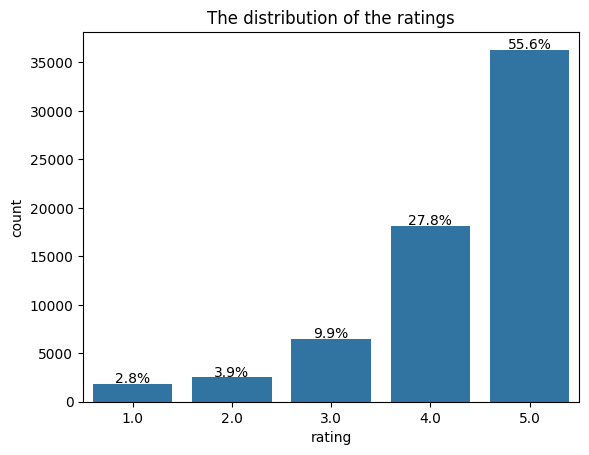

In [18]:
# Create the bar plot and provide observations
def hist_bar_plot(df: pd.DataFrame, num_var: str, graph_title:str=None, annotation= True):
  """
  Creates a barplot for a numerical variable in a Pandas DataFrame,
  and displays the percentage of each category on top of the bars.

  Args:
      df (pd.DataFrame): The Pandas DataFrame containing the data.
      num_var (str): The name of the numerical variable to create the boxplot for.
      graph_title (str): Title for the plot
      annotation: Indicate if the percentage annotation needs to be shown or not.

  Returns:
      None. This function creates a barplot and displays it using plt.show().
  """
  df_freq = pd.DataFrame(df.groupby(num_var).count())
  total_count = df_freq['user_id'].sum()

  # Calculate percentages
  df_freq['percentage'] = (df_freq['user_id'] / total_count) * 100

  # Create the plots with a shared axis using seaborn
  sns.barplot(data=df_freq, x=df_freq.index, y='user_id')

  # Label the x-axis with the variable name
  plt.title(graph_title)
  plt.xlabel(num_var)
  plt.ylabel("count")

  # Add percentage labels on top of bars
  for i, v in enumerate(df_freq['percentage']):
    plt.text(i, v*total_count/100+500, f"{v:.1f}%", va='center', ha='center', fontsize=10)

  # Display the barplot
  plt.show()

hist_bar_plot(df_final, 'rating', 'The distribution of the ratings')

A rating of 5 is the most common, with 55.6% of the cases (more than 35000 entries), followed by a rating of 4 (27.8%), 3 (9.9%), 2 (3.9%) and 1 (2.8%). This makes sense when looking at the information seen earlier with the `info()` function: the average rating is about 4.3!

### **Checking the number of unique users and items in the dataset**

In [19]:
# Number of total rows in the data and number of unique user id and product id in the data
print(f"There are {df_final.shape[0]} rows in the data")
df_final.nunique()

There are 65290 rows in the data


,0
user_id,1540
prod_id,5689
rating,5


There 1540 unique users and 5689 unique products on the total of 65290 ratings.

### **Users with the most number of ratings**

In [20]:
# Top 10 users based on the number of ratings
df_final['user_id'].value_counts()[0:10]

,count
user_id,
ADLVFFE4VBT8,295
A3OXHLG6DIBRW8,230
A1ODOGXEYECQQ8,217
A36K2N527TXXJN,212
A25C2M3QF9G7OQ,203
A680RUE1FDO8B,196
A1UQBFCERIP7VJ,193
A22CW0ZHY3NJH8,193
AWPODHOB4GFWL,184


The top 10 of users with the most ratings all gave at least 179 ratings, with a maximum of 295 ratings for user `ADLVFFE4VBT8`.

Remark: I would normally change the user and product ids to something easier (with the `sklearn.preprocessing LabelEncoder`), but as we will keep on referring to these more complicated ids further down, I will keep them.

**Now that we have explored and prepared the data, let's build the first recommendation system.**

## **Model 1: Rank Based Recommendation System**

In [21]:
# Calculate the average rating for each product
average_rating = df_final.groupby('prod_id')['rating'].mean()

# Calculate the count of ratings for each product
count_rating = df_final.groupby('prod_id')['rating'].count()

# Create a dataframe with calculated average and count of ratings
final_rating = pd.DataFrame({'avg_rating':average_rating, 'count_rating':count_rating})

# Sort the dataframe by average of ratings in the descending order
final_rating = final_rating.sort_values('avg_rating', ascending=False)

# See the first five records of the "final_rating" dataset
print(final_rating[0:5])

            avg_rating  count_rating
prod_id                             
B00LGQ6HL8         5.0             5
B003DZJQQI         5.0            14
B005FDXF2C         5.0             7
B00I6CVPVC         5.0             7
B00B9KOCYA         5.0             8


Many products have an average rating of 5, with a different amounts of ratings.

In [22]:
# Defining a function to get the top n products based on the highest average rating and minimum interactions
def top_n_products(df, n, min_interactions=50): # We set min_interactions default to 50 based on the next question
  """
  Finds the top 'n' products with the highest average rating, considering only products with at least 'min_interactions'.

  Args:
    df: Pandas DataFrame containing product information.
    n: Number of top products to return.
    min_interactions: Minimum number of interactions (e.g., ratings) for a product to be considered.

  Returns:
    Pandas DataFrame containing the top 'n' products sorted by average rating in descending order.
  """
  # Finding products with minimum number of interactions
  prod_over_threshold = df[df['count_rating'] > min_interactions]
  # Sorting values with respect to average rating
  prod_over_threshold = prod_over_threshold.sort_values(by='avg_rating', ascending=False)

  return prod_over_threshold[:n]

### **Recommending top 5 products with 50 minimum interactions based on popularity**

In [23]:
top_n_products(final_rating, 5, 50)

,avg_rating,count_rating
prod_id,,
B001TH7GUU,4.871795,78
B003ES5ZUU,4.864130,184
B0019EHU8G,4.855556,90
B006W8U2MU,4.824561,57
B000QUUFRW,4.809524,84


The top five products with minimal 50 interactions all have an average rating above 4.8.

### **Recommending top 5 products with 100 minimum interactions based on popularity**

In [24]:
top_n_products(final_rating, 5, 100)

,avg_rating,count_rating
prod_id,,
B003ES5ZUU,4.864130,184
B000N99BBC,4.772455,167
B007WTAJTO,4.701220,164
B002V88HFE,4.698113,106
B004CLYEDC,4.669492,118


The top five products with minimal 50 interactions all have an average rating above 4.66.

We have recommended the **top 5** products by using the popularity recommendation system. Now, let's build a recommendation system using **collaborative filtering.**

## **Model 2: Collaborative Filtering Recommendation System**

### **Building a baseline user-user similarity based recommendation system**

- Below, we are building **similarity-based recommendation systems** using `cosine` similarity and using **KNN to find similar users** which are the nearest neighbor to the given user.  
- We will be using a new library, called `surprise`, to build the remaining models. Let's first import the necessary classes and functions from this library.

In [25]:
# To compute the accuracy of models
from surprise import accuracy

# Class is used to parse a file containing ratings, data should be in structure - user ; item ; rating
from surprise.reader import Reader

# Class for loading datasets
from surprise.dataset import Dataset

# For tuning model hyperparameters
from surprise.model_selection import GridSearchCV

# For splitting the rating data in train and test datasets
from surprise.model_selection import train_test_split

# For implementing similarity-based recommendation system
from surprise.prediction_algorithms.knns import KNNBasic

# For implementing matrix factorization based recommendation system
from surprise.prediction_algorithms.matrix_factorization import SVD

# for implementing K-Fold cross-validation
from surprise.model_selection import KFold

# For implementing clustering-based recommendation system
from surprise import CoClustering

**Before building the recommendation systems, let's  go over some basic terminologies we are going to use:**

**Relevant item:** An item (product in this case) that is actually **rated higher than the threshold rating** is relevant, if the **actual rating is below the threshold then it is a non-relevant item**.  

**Recommended item:** An item that's **predicted rating is higher than the threshold is a recommended item**, if the **predicted rating is below the threshold then that product will not be recommended to the user**.  


**False Negative (FN):** It is the **frequency of relevant items that are not recommended to the user**. If the relevant items are not recommended to the user, then the user might not buy the product/item. This would result in the **loss of opportunity for the service provider**, which they would like to minimize.

**False Positive (FP):** It is the **frequency of recommended items that are actually not relevant**. In this case, the recommendation system is not doing a good job of finding and recommending the relevant items to the user. This would result in **loss of resources for the service provider**, which they would also like to minimize.

**Recall:** It is the **fraction of actually relevant items that are recommended to the user**, i.e., if out of 10 relevant products, 6 are recommended to the user then recall is 0.60. Higher the value of recall better is the model. It is one of the metrics to do the performance assessment of classification models.

**Precision:** It is the **fraction of recommended items that are relevant actually**, i.e., if out of 10 recommended items, 6 are found relevant by the user then precision is 0.60. The higher the value of precision better is the model. It is one of the metrics to do the performance assessment of classification models.

**While making a recommendation system, it becomes customary to look at the performance of the model. In terms of how many recommendations are relevant and vice-versa, below are some most used performance metrics used in the assessment of recommendation systems.**

### **Precision@k, Recall@ k, and F1-score@k**

**Precision@k** - It is the **fraction of recommended items that are relevant in `top k` predictions**. The value of k is the number of recommendations to be provided to the user. One can choose a variable number of recommendations to be given to a unique user.  


**Recall@k** - It is the **fraction of relevant items that are recommended to the user in `top k` predictions**.

**F1-score@k** - It is the **harmonic mean of Precision@k and Recall@k**. When **precision@k and recall@k both seem to be important** then it is useful to use this metric because it is representative of both of them.

### **Some useful functions**

- Below function takes the **recommendation model** as input and gives the **precision@k, recall@k, and F1-score@k** for that model.  
- To compute **precision and recall**, **top k** predictions are taken under consideration for each user.
- We will use the precision and recall to compute the F1-score.

In [26]:
def precision_recall_at_k(model, k = 10, threshold = 3.5):
    """Return precision and recall at k metrics for each user"""

    # First map the predictions to each user
    user_est_true = defaultdict(list)

    # Making predictions on the test data
    predictions = model.test(testset)

    for uid, _, true_r, est, _ in predictions:
        user_est_true[uid].append((est, true_r))

    precisions = dict()
    recalls = dict()
    for uid, user_ratings in user_est_true.items():

        # Sort user ratings by estimated value
        user_ratings.sort(key = lambda x: x[0], reverse = True)

        # Number of relevant items
        n_rel = sum((true_r >= threshold) for (_, true_r) in user_ratings)

        # Number of recommended items in top k
        n_rec_k = sum((est >= threshold) for (est, _) in user_ratings[:k])

        # Number of relevant and recommended items in top k
        n_rel_and_rec_k = sum(((true_r >= threshold) and (est >= threshold))
                              for (est, true_r) in user_ratings[:k])

        # Precision@K: Proportion of recommended items that are relevant
        # When n_rec_k is 0, Precision is undefined. Therefore, we are setting Precision to 0 when n_rec_k is 0

        precisions[uid] = n_rel_and_rec_k / n_rec_k if n_rec_k != 0 else 0

        # Recall@K: Proportion of relevant items that are recommended
        # When n_rel is 0, Recall is undefined. Therefore, we are setting Recall to 0 when n_rel is 0

        recalls[uid] = n_rel_and_rec_k / n_rel if n_rel != 0 else 0

    # Mean of all the predicted precisions are calculated.
    precision = round((sum(prec for prec in precisions.values()) / len(precisions)), 3)

    # Mean of all the predicted recalls are calculated.
    recall = round((sum(rec for rec in recalls.values()) / len(recalls)), 3)

    accuracy.rmse(predictions)

    print('Precision: ', precision) # Command to print the overall precision

    print('Recall: ', recall) # Command to print the overall recall

    print('F_1 score: ', round((2*precision*recall)/(precision+recall), 3)) # Formula to compute the F-1 score

**Hints:**

- To compute **precision and recall**, a **threshold of 3.5 and k value of 10 can be considered for the recommended and relevant ratings**.
- Think about the performance metric to choose.

Below we are loading the **`rating` dataset**, which is a **pandas DataFrame**, into a **different format called `surprise.dataset.DatasetAutoFolds`**, which is required by this library. To do this, we will be **using the classes `Reader` and `Dataset`.**

In [27]:
# Instantiating Reader scale with expected rating scale
reader = Reader(rating_scale=(1, 5))
# Loading the rating dataset
data = Dataset.load_from_df(df_final[['user_id', 'prod_id', 'rating']], reader)
# Splitting the data into train and test datasets, I will use a 20-80 split
trainset, testset = train_test_split(data, test_size=0.20, random_state=1)

Now, we are **ready to build the first baseline similarity-based recommendation system** using the cosine similarity.

### **Building the user-user Similarity-based Recommendation System**

In [28]:
# Declaring the similarity options
simulation_options = {'name': 'cosine', 'user_based': True} # Using cosine, as requested in the question

# Initialize the KNNBasic model using sim_options declared, Verbose = False, and setting random_state = 1
sim_user_user = KNNBasic(sim_options=simulation_options, verbose=False, random_state=1)

# Fit the model on the training data
sim_user_user.fit(trainset)

# Let us compute precision@k, recall@k, and f_1 score using the precision_recall_at_k function defined above
precision_recall_at_k(sim_user_user)

RMSE: 1.0260
Precision:  0.844
Recall:  0.862
F_1 score:  0.853


**Observations:**



*   The RMSE tells us that the overall predicted rating is about 1.03 away from the overall actual rating.
*   Precision: a value of 84.4% means that out of the 10 recommended products, between 8 and 9 on average are relevant.
*   Recall: a value of 86.2% means that out of 10 relevant products, between 8 and 9 on average are recommended.
*   F1 score: a value of 85.3% is pretty good. In order words, relevant products were recommended and the recommended products were relevant.



Let's now **predict rating for a user with `userId=A3LDPF5FMB782Z` and `productId=1400501466`** as shown below. Here the user has already interacted or watched the product with productId '1400501466' and given a rating of 5.

In [29]:
# Predicting rating for a sample user with an interacted product
sim_user_user.predict('A3LDPF5FMB782Z', '1400501466', r_ui=5, verbose=True)

user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 3.33   {'actual_k': 6, 'was_impossible': False}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=3.3333333333333335, details={'actual_k': 6, 'was_impossible': False})

**Observations:**

The user with ID `A3LDPF5FMB782Z` gave a rating of 5 to product `1400501466`, but the user-user-similariy based system predicts this user would give a rating of 3.3 (on average), which is pretty far off, given the RMSE of 1.03.

Below is the **list of users who have not seen the product with product id "1400501466"**.

In [30]:
# Find unique user_id where prod_id is not equal to "1400501466"
data_cleaned = df_final[df_final.prod_id != "1400501466"]
answer = data_cleaned.user_id.unique()
print(answer)

['A2ZR3YTMEEIIZ4' 'A3CLWR1UUZT6TG' 'A5JLAU2ARJ0BO' ... 'A215WH6RUDUCMP'
 'A38C12950IM24P' 'A2J4XMWKR8PPD0']


For the next question, we check if the user `A34BZM6S9L7QI4` is in the list of users which have not seen this product yet.

In [31]:
'A34BZM6S9L7QI4' in answer

True

* It can be observed from the above list that **user "A34BZM6S9L7QI4" has not seen the product with productId "1400501466"** as this userId is a part of the above list.

**Below we are predicting rating for `userId=A34BZM6S9L7QI4` and `prod_id=1400501466`.**

In [32]:
# Predicting rating for a sample user with a non interacted product
sim_user_user.predict('A34BZM6S9L7QI4', '1400501466', verbose=True)

user: A34BZM6S9L7QI4 item: 1400501466 r_ui = None   est = 1.99   {'actual_k': 2, 'was_impossible': False}


Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=1.991150442477876, details={'actual_k': 2, 'was_impossible': False})

**Observations:**

The model predicts that user `A34BZM6S9L7QI4` will not like the product that much and would only give a rating of about 2.

### **Improving similarity-based recommendation system by tuning its hyperparameters**

Below, we will be tuning hyperparameters for the `KNNBasic` algorithm. Let's try to understand some of the hyperparameters of the KNNBasic algorithm:

- **k** (int) – The (max) number of neighbors to take into account for aggregation. Default is 40.
- **min_k** (int) – The minimum number of neighbors to take into account for aggregation. If there are not enough neighbors, the prediction is set to the global mean of all ratings. Default is 1.
- **sim_options** (dict) – A dictionary of options for the similarity measure. And there are four similarity measures available in surprise -
    - cosine
    - msd (default)
    - Pearson
    - Pearson baseline

In [37]:
# Setting up parameter grid to tune the hyperparameters
parameters_grid = {'k': [20, 40, 80],
              'min_k': [1, 3, 5, 8],
              'sim_options': {'name': ["cosine","msd","pearson","pearson_baseline"],
                              'user_based': [True]}
              }

# Performing 3-fold cross-validation to tune the hyperparameters
grid_search = GridSearchCV(KNNBasic, parameters_grid, measures=['rmse'], cv=3, n_jobs=-1)

# Fitting the data
grid_search.fit(data)

# Best RMSE score
print(f"The best obtained RMSE score was: {grid_search.best_score['rmse']}")

# Combination of parameters that gave the best RMSE score
print(f"The corresponding parameter combination was: {grid_search.best_params['rmse']}")

The best obtained RMSE score was: 0.9711728106720597
The corresponding parameter combination was: {'k': 80, 'min_k': 5, 'sim_options': {'name': 'cosine', 'user_based': True}}


Once the grid search is **complete**, we can get the **optimal values for each of those hyperparameters**.

We found during the search we did that better set of hyperparameters was:


*   k = 80
*   minimum number of neighbours = 5
*   cosine similarity measure (user based)



Now, let's build the **final model by using tuned values of the hyperparameters**, which we received by using **grid search cross-validation**.

In [44]:
# Using the optimal similarity measure for user-user based collaborative filtering
simulation_options = {'name': 'cosine',
               'user_based': True} #, "min_support":2}

# Creating an instance of KNNBasic with optimal hyperparameter values
sim_user_user_optimized = KNNBasic(sim_options=simulation_options, k=80, min_k=5, random_state=1, verbose=False)

# Training the algorithm on the trainset
sim_user_user_optimized.fit(trainset)

# Let us compute precision@k and recall@k also with k =10
precision_recall_at_k(sim_user_user_optimized)

RMSE: 0.9741
Precision:  0.836
Recall:  0.895
F_1 score:  0.864


**Observations:**

*   The RMSE when down from 1.03 to 0.97, which is an improvement.
*   Precision: dropped slightly from 84.4 to 83.6%
*   Recall: went up from 86.2% to 89.5%
*   F1 score: a value of 86.4% is higher than the previous one.

We can conclude that the grid search let to a slightly better performing model.

### **Steps:**
- **Predict rating for the user with `userId="A3LDPF5FMB782Z"`, and `prod_id= "1400501466"` using the optimized model**
- **Predict rating for `userId="A34BZM6S9L7QI4"` who has not interacted with `prod_id ="1400501466"`, by using the optimized model**
- **Compare the output with the output from the baseline model**

In [42]:
# Use sim_user_user_optimized model to recommend for userId "A3LDPF5FMB782Z" and productId 1400501466
sim_user_user_optimized.predict('A3LDPF5FMB782Z', '1400501466', r_ui=5, verbose=True)

user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 3.33   {'actual_k': 6, 'was_impossible': False}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=3.3333333333333335, details={'actual_k': 6, 'was_impossible': False})

In [43]:
# Use sim_user_user_optimized model to recommend for userId "A34BZM6S9L7QI4" and productId "1400501466"
sim_user_user_optimized.predict('A34BZM6S9L7QI4', '1400501466', verbose=True)

user: A34BZM6S9L7QI4 item: 1400501466 r_ui = None   est = 4.30   {'was_impossible': True, 'reason': 'Not enough neighbors.'}


Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=4.296427477408486, details={'was_impossible': True, 'reason': 'Not enough neighbors.'})

**Observations:**

Compared to the previous model, we see that the predicted rating for this item for user `A3LDPF5FMB782Z` is now 3.3, which is the same prediction as made before (even if the real rating was 5). So there is no improvement there, even tough this is just one specific case.

The expected rating for user `A34BZM6S9L7QI4` went also up to 4.3 (from 2). The prediction says however as well that a correct prediction using the model was impossible, as there were not enough neighbours in this model. So this value is in fact just the overall average that is given in this case (see also the `describe()` function we used earlier on this dataset). I tried other combinations of hyperparameters more, but none of them seemed to solve this. This might be for the user-user model a quite isolated user.

### **Identifying similar users to a given user (nearest neighbors)**

We can also find out **similar users to a given user** or its **nearest neighbors** based on this KNNBasic algorithm. Below, we are finding the 5 most similar users to the first user in the list with internal id 0, based on the `msd` distance metric.

In [45]:
# 0 is the inner id of the above user
sim_user_user_optimized.get_neighbors(0,5) # msd is the default distance metric

[1, 10, 17, 18, 28]

Users 1, 10, 17, 18 and 28 are most similar to user 0.

### **Implementing the recommendation algorithm based on optimized KNNBasic model**

Below we will be implementing a function where the input parameters are:

- data: A **rating** dataset
- user_id: A user id **against which we want the recommendations**
- top_n: The **number of products we want to recommend**
- algo: the algorithm we want to use **for predicting the ratings**
- The output of the function is a **set of top_n items** recommended for the given user_id based on the given algorithm

In [46]:
def get_recommendations(data, user_id, top_n, algo):

    # Creating an empty list to store the recommended product ids
    recommendations = []

    # Creating an user item interactions matrix
    user_item_interactions_matrix = data.pivot(index = 'user_id', columns = 'prod_id', values = 'rating')

    # Extracting those product ids which the user_id has not interacted yet
    non_interacted_products = user_item_interactions_matrix.loc[user_id][user_item_interactions_matrix.loc[user_id].isnull()].index.tolist()

    # Looping through each of the product ids which user_id has not interacted yet
    for item_id in non_interacted_products:

        # Predicting the ratings for those non interacted product ids by this user
        est = algo.predict(user_id, item_id).est

        # Appending the predicted ratings
        recommendations.append((item_id, est))

    # Sorting the predicted ratings in descending order
    recommendations.sort(key = lambda x: x[1], reverse = True)

    return recommendations[:top_n] # Returing top n highest predicted rating products for this user

**Predicting top 5 products for userId = "A3LDPF5FMB782Z" with similarity based recommendation system**

In [40]:
# Making top 5 recommendations for user_id "A3LDPF5FMB782Z" with a similarity-based recommendation engine
top_products = get_recommendations(df_final,"A3LDPF5FMB782Z", 5, sim_user_user_optimized)

In [41]:
# Building the dataframe for above recommendations with columns "prod_id" and "predicted_ratings"
pd.DataFrame(top_products, columns = ['prod_id', 'predicted_ratings'])

,prod_id,predicted_ratings
0,B00005LEN4,5
1,B000067RT6,5
2,B0000X0VCY,5
3,B000ENUCR4,5
4,B000TXEE14,5


The top 5 products recommended to user `A3LDPF5FMB782Z` all have a predicted rating of 5.

### **Item-Item Similarity-based Collaborative Filtering Recommendation System**

* Above we have seen **similarity-based collaborative filtering** where similarity is calculated **between users**. Now let us look into similarity-based collaborative filtering where similarity is seen **between items**.

In [47]:
# Declaring the similarity options
simulation_options = {'name': 'cosine',
               'user_based': False}

# KNN algorithm is used to find desired similar items. Use random_state=1
sim_item_item = KNNBasic(sim_options=simulation_options, random_state=1, verbose=False)

# Train the algorithm on the trainset, and predict ratings for the test set
sim_item_item.fit(trainset)

# Let us compute precision@k, recall@k, and f_1 score with k = 10
precision_recall_at_k(sim_item_item)

RMSE: 1.0147
Precision:  0.826
Recall:  0.853
F_1 score:  0.839


**Observation:**

*   The RMSE tells us that the overall predicted rating is about 1.01 away from the overall actual rating.
*   Precision: a value of 82.6% means that out of the 10 recommended products, between 8 and 9 on average are relevant.
*   Recall: a value of 85.3% means that out of 10 relevant products, between 8 and 9 on average are recommended.
*   F1 score: a value of 83.9% is pretty good. In order words, relevant products were recommended and the recommended products were relevant.

Let's now **predict a rating for a user with `userId = A3LDPF5FMB782Z` and `prod_Id = 1400501466`** as shown below. Here the user has already interacted or watched the product with productId "1400501466".

In [48]:
# Predicting rating for a sample user with an interacted product
sim_item_item.predict("A3LDPF5FMB782Z", "1400501466", r_ui=5, verbose=True)

user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 4.30   {'actual_k': 20, 'was_impossible': False}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=4.3, details={'actual_k': 20, 'was_impossible': False})

**Observation:**

The prediction of a rating of 4.3 is pretty close to the real rating of 5.

Below we are **predicting rating for the `userId = A34BZM6S9L7QI4` and `prod_id = 1400501466`**.

In [49]:
# Predicting rating for a sample user with a non interacted product
sim_item_item.predict("A34BZM6S9L7QI4", "1400501466", verbose=True)

user: A34BZM6S9L7QI4 item: 1400501466 r_ui = None   est = 4.00   {'actual_k': 4, 'was_impossible': False}


Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=4.0, details={'actual_k': 4, 'was_impossible': False})

**Observation:**

The prediction of a rating for user `A34BZM6S9L7QI4` is for the item `1400501466` this time 4. Note that there were enough neighbours for the item to come up with the estimation (in contrast to the user-user model).

### **Hyperparameter tuning the item-item similarity-based model**
- Use the following values for the param_grid and tune the model.
  - 'k': [10, 20, 30]
  - 'min_k': [3, 6, 9]
  - 'sim_options': {'name': ['msd', 'cosine']
  - 'user_based': [False]
- Use GridSearchCV() to tune the model using the 'rmse' measure
- Print the best score and best parameters

In [54]:
# Setting up parameter grid to tune the hyperparameters
parameters_grid = {'k': [10, 20, 30],
              'min_k': [3, 6, 9],
              'sim_options': {'name': ["msd","cosine"],
                              'user_based': [False]}
              }

# Performing 3-fold cross validation to tune the hyperparameters
grid_search = GridSearchCV(KNNBasic, parameters_grid, measures=['rmse'], cv=3, n_jobs=-1)

# Fitting the data
grid_search.fit(data)

# Find the best RMSE score
print(f"The best obtained RMSE score was: {grid_search.best_score['rmse']}")

# Find the combination of parameters that gave the best RMSE score
print(f"The corresponding parameter combination was: {grid_search.best_params['rmse']}")

The best obtained RMSE score was: 0.9748455658028736
The corresponding parameter combination was: {'k': 20, 'min_k': 6, 'sim_options': {'name': 'msd', 'user_based': False}}


Once the **grid search** is complete, we can get the **optimal values for each of those hyperparameters as shown above.**

We found after a gridsearch the following hyperparameters:



*   k = 20
*   minimal numbers = 6
*   simulation option msd (not user based)



Now let's build the **final model** by using **tuned values of the hyperparameters** which we received by using grid search cross-validation.

### **Use the best parameters from GridSearchCV to build the optimized item-item similarity-based model. Compare the performance of the optimized model with the baseline model.**

In [55]:
# Using the optimal similarity measure for item-item based collaborative filtering
simulation_options = {'name': 'msd',
               'user_based': False} #, "min_support":2}

# Creating an instance of KNNBasic with optimal hyperparameter values
sim_item_item_optimized = KNNBasic(sim_options=simulation_options, k=20, min_k=6, random_state=1, verbose=False)

# Training the algorithm on the trainset
sim_item_item_optimized.fit(trainset)

# Let us compute precision@k and recall@k, f1_score and RMSE
precision_recall_at_k(sim_item_item_optimized)

RMSE: 0.9752
Precision:  0.83
Recall:  0.893
F_1 score:  0.86


**Observations:**

*   The RMSE when down from 1.01 to 0.975, which is an improvement compared to the baseline.
*   Precision: increases slightly from 82.6 to 83%
*   Recall: went up from 85.3% to 89.3%
*   F1 score: a value of 86% is higher than the previous one (83.9%).

We can conclude that the grid search lead to a slightly better performing model.


### **Steps:**
- **Predict rating for the user with `userId="A3LDPF5FMB782Z"`, and `prod_id= "1400501466"` using the optimized model**
- **Predict rating for `userId="A34BZM6S9L7QI4"` who has not interacted with `prod_id ="1400501466"`, by using the optimized model**
- **Compare the output with the output from the baseline model**

In [56]:
# Use sim_item_item_optimized model to recommend for userId "A3LDPF5FMB782Z" and productId "1400501466"
sim_item_item_optimized.predict("A3LDPF5FMB782Z", "1400501466", r_ui=5, verbose=True)

user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 4.62   {'actual_k': 20, 'was_impossible': False}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=4.617647058823531, details={'actual_k': 20, 'was_impossible': False})

In [57]:
# Use sim_item_item_optimized model to recommend for userId "A34BZM6S9L7QI4" and productId "1400501466"
sim_item_item_optimized.predict("A34BZM6S9L7QI4", "1400501466", verbose=True)

user: A34BZM6S9L7QI4 item: 1400501466 r_ui = None   est = 4.30   {'was_impossible': True, 'reason': 'Not enough neighbors.'}


Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=4.296427477408486, details={'was_impossible': True, 'reason': 'Not enough neighbors.'})

**Observations:**

For the user `A3LDPF5FMB782Z` the predicted rating of 4.62 is close to the actual rating of 5 and closer than the prediction of the baseline model (4.3).

For the user `A34BZM6S9L7QI4` the predicted rating is this time 4.3, but with the remark that there were not enough neighbours (so this is again just the overall average). The baseline model predicted 4 before.

### **Identifying similar items to a given item (nearest neighbors)**

We can also find out **similar items** to a given item or its nearest neighbors based on this **KNNBasic algorithm**. Below we are finding the 5 most similar items to the item with internal id 0 based on the `msd` distance metric.

In [58]:
sim_item_item_optimized.get_neighbors(0, k=5)

[2, 4, 9, 12, 13]

Items 2, 4, 9, 12 and 13 are predicted to be the most similar to item with id 0.


**Predicting top 5 products for userId = "A1A5KUIIIHFF4U" with similarity based recommendation system.**

**Hint:** Use the get_recommendations() function.

In [59]:
# Making top 5 recommendations for user_id A1A5KUIIIHFF4U with similarity-based recommendation engine.
top_products = get_recommendations(df_final, "A1A5KUIIIHFF4U", 5, sim_item_item_optimized)

In [60]:
# Building the dataframe for above recommendations with columns "prod_id" and "predicted_ratings"
pd.DataFrame(top_products, columns = ['prod_id', 'predicted_ratings'])

,prod_id,predicted_ratings
0,1400532655,4.296427
1,1400599997,4.296427
2,9983891212,4.296427
3,B00000DM9W,4.296427
4,B00000J1V5,4.296427


The user `A1A5KUIIIHFF4U` gets 5 recommendations with the same rating, which is the overall average rating. What does this mean? Let's look at what the prediction says for one specific item:

In [62]:
# Use sim_item_item_optimized model to recommend for userId "A34BZM6S9L7QI4" and productId "1400501466"
sim_item_item_optimized.predict("A1A5KUIIIHFF4U", "1400532655", verbose=True)

user: A1A5KUIIIHFF4U item: 1400532655 r_ui = None   est = 4.30   {'was_impossible': True, 'reason': 'Not enough neighbors.'}


Prediction(uid='A1A5KUIIIHFF4U', iid='1400532655', r_ui=None, est=4.296427477408486, details={'was_impossible': True, 'reason': 'Not enough neighbors.'})

Here the model gives the average again because there are not enough neighbours for this item-item based collaborative model.

Now as we have seen **similarity-based collaborative filtering algorithms**, let us now get into **model-based collaborative filtering algorithms**.

### **Model 3: Model-Based Collaborative Filtering - Matrix Factorization**

Model-based Collaborative Filtering is a **personalized recommendation system**, the recommendations are based on the past behavior of the user and it is not dependent on any additional information. We use **latent features** to find recommendations for each user.

### Singular Value Decomposition (SVD)

SVD is used to **compute the latent features** from the **user-item matrix**. But SVD does not work when we **miss values** in the **user-item matrix**.

In [63]:
# Using SVD matrix factorization. Use random_state = 1
svd = SVD(random_state=1)

# Training the algorithm on the trainset
svd.fit(trainset)

# Use the function precision_recall_at_k to compute precision@k, recall@k, F1-Score, and RMSE
precision_recall_at_k(svd)

RMSE: 0.9104
Precision:  0.837
Recall:  0.88
F_1 score:  0.858


**Observations:**

*   The RMSE of 0.91 is the best we saw so far
*   Precision: 83.7%
*   Recall: 88%
*   F1 score: 85.8% is a high score, but some of the optimized models before scored better

**Let's now predict the rating for a user with `userId = "A3LDPF5FMB782Z"` and `prod_id = "1400501466`.**

In [64]:
# Making prediction
svd.predict("A3LDPF5FMB782Z", "1400501466", r_ui=5, verbose=True)

user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 4.09   {'was_impossible': False}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=4.094312160755627, details={'was_impossible': False})

**Observations:**

The predicted rating is 4.1 for the svd model, whereas the real rating was 5.



**Below we are predicting rating for the `userId = "A34BZM6S9L7QI4"` and `productId = "1400501466"`.**

In [65]:
# Making prediction
svd.predict("A34BZM6S9L7QI4", "1400501466",  verbose=True)

user: A34BZM6S9L7QI4 item: 1400501466 r_ui = None   est = 4.05   {'was_impossible': False}


Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=4.051141373805704, details={'was_impossible': False})

**Observations:**

The predicted rating is 4.05 for the svd model, which is in line with previous models.

### **Improving Matrix Factorization based recommendation system by tuning its hyperparameters**

Below we will be tuning only three hyperparameters:
- **n_epochs**: The number of iterations of the SGD algorithm.
- **lr_all**: The learning rate for all parameters.
- **reg_all**: The regularization term for all parameters.

In [69]:
# Set the parameter space to tune
parameters_grid = {'n_epochs': [10, 20, 30], 'lr_all': [0.001, 0.005, 0.01], 'reg_all': [0.2, 0.4, 0.6]}

# Performing 3-fold gridsearch cross-validation
grid_search = GridSearchCV(SVD, parameters_grid, measures=['rmse'], cv=3, n_jobs=-1)

# Fitting data
grid_search.fit(data)

# Best RMSE score
print(f"The best obtained RMSE score was: {grid_search.best_score['rmse']}")

# Combination of parameters that gave the best RMSE score
print(f"The corresponding parameter combination was: {grid_search.best_params['rmse']}")

The best obtained RMSE score was: 0.9005400001607171
The corresponding parameter combination was: {'n_epochs': 20, 'lr_all': 0.01, 'reg_all': 0.2}


We found after a grid search the best parameters to be:


*   epochs: 20
*   learning rate: 0.01
*   regularization terms: 0.2



Now, we will **the build final model** by using **tuned values** of the hyperparameters, which we received using grid search cross-validation above.

In [71]:
# Build the optimized SVD model using optimal hyperparameter search. Use random_state=1
svd_optimized = SVD(n_epochs=20, lr_all=0.01, reg_all=0.2, random_state=1)

# Train the algorithm on the trainset
svd_optimized=svd_optimized.fit(trainset)

# Use the function precision_recall_at_k to compute precision@k, recall@k, F1-Score, and RMSE
precision_recall_at_k(svd_optimized)

RMSE: 0.9014
Precision:  0.841
Recall:  0.88
F_1 score:  0.86


**Observations:**

*   The RMSE when down from 0.91 to 0.9, which is a small improvement.
*   Precision: increases slightly from 83.7 to 84.1%
*   Recall: stayed at 88%
*   F1 score: a value of 86% is only a little bit higher than the previous one (85.8%).

We can conclude that the grid search let to a slightly better performing model than the non-tuned one.

### **Steps:**
- **Predict rating for the user with `userId="A3LDPF5FMB782Z"`, and `prod_id= "1400501466"` using the optimized model**
- **Predict rating for `userId="A34BZM6S9L7QI4"` who has not interacted with `prod_id ="1400501466"`, by using the optimized model**
- **Compare the output with the output from the baseline model**

In [72]:
# Use svd_algo_optimized model to recommend for userId "A3LDPF5FMB782Z" and productId "1400501466"
svd_optimized.predict("A3LDPF5FMB782Z", "1400501466", r_ui=5, verbose=True)

user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 4.09   {'was_impossible': False}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=4.090441179731308, details={'was_impossible': False})

In [73]:
# Use svd_algo_optimized model to recommend for userId "A34BZM6S9L7QI4" and productId "1400501466"
svd_optimized.predict("A34BZM6S9L7QI4", "1400501466", verbose=True)

user: A34BZM6S9L7QI4 item: 1400501466 r_ui = None   est = 4.06   {'was_impossible': False}


Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=4.06446285064312, details={'was_impossible': False})

**Observations:**

For the user `A3LDPF5FMB782Z` the predicted rating of 4.1 is close to the actual rating of 5 and at the same level as the baseline model.
For the user `A34BZM6S9L7QI4` the predicted rating is this time 4.06. The baseline model predicted 4.05 before.

### **Conclusion and Recommendations**

We first made a rank-based recommendation system. Then we made 3 baseline models (user-user, item-item and SVD) and we optimized them with a grid search.

We summarize the predictions for the 6 models once again here below.

**Precision/ Recall/ F1:**


In [74]:
print("Baseline user-user similarity-based collaborative filtering recommendation system:")
precision_recall_at_k(sim_user_user)
print("-"*50)
print("Optimized user-user similarity-based collaborative filtering recommendation system:")
precision_recall_at_k(sim_user_user_optimized)
print("-"*50)
print("Baseline item-item similarity-based collaborative filtering recommendation system:")
precision_recall_at_k(sim_item_item)
print("-"*50)
print("Optimized item-item similarity-based collaborative filtering recommendation system:")
precision_recall_at_k(sim_item_item_optimized)
print("-"*50)
print("Baseline Model-Based Collaborative Filtering - Matrix Factorization:")
precision_recall_at_k(svd)
print("-"*50)
print("Optimized Model-Based Collaborative Filtering - Matrix Factorization:")
precision_recall_at_k(svd_optimized)

Baseline user-user similarity-based collaborative filtering recommendation system:
RMSE: 1.0260
Precision:  0.844
Recall:  0.862
F_1 score:  0.853
--------------------------------------------------
Optimized user-user similarity-based collaborative filtering recommendation system:
RMSE: 0.9741
Precision:  0.836
Recall:  0.895
F_1 score:  0.864
--------------------------------------------------
Baseline item-item similarity-based collaborative filtering recommendation system:
RMSE: 1.0147
Precision:  0.826
Recall:  0.853
F_1 score:  0.839
--------------------------------------------------
Optimized item-item similarity-based collaborative filtering recommendation system:
RMSE: 0.9752
Precision:  0.83
Recall:  0.893
F_1 score:  0.86
--------------------------------------------------
Baseline Model-Based Collaborative Filtering - Matrix Factorization:
RMSE: 0.9104
Precision:  0.837
Recall:  0.88
F_1 score:  0.858
--------------------------------------------------
Optimized Model-Based Col

**Predictions for the user `A3LDPF5FMB782Z` for the item `1400501466` (known rating of 5):**

In [75]:
print("Baseline user-user similarity-based collaborative filtering recommendation system:")
sim_user_user.predict("A3LDPF5FMB782Z", "1400501466", r_ui=5, verbose=True)
print("-"*50)
print("Optimized user-user similarity-based collaborative filtering recommendation system:")
sim_user_user_optimized.predict("A3LDPF5FMB782Z", "1400501466", r_ui=5, verbose=True)
print("-"*50)
print("Baseline item-item similarity-based collaborative filtering recommendation system:")
sim_item_item.predict("A3LDPF5FMB782Z", "1400501466", r_ui=5, verbose=True)
print("-"*50)
print("Optimized item-item similarity-based collaborative filtering recommendation system:")
sim_item_item_optimized.predict("A3LDPF5FMB782Z", "1400501466", r_ui=5, verbose=True)
print("-"*50)
print("Baseline Model-Based Collaborative Filtering - Matrix Factorization:")
svd.predict("A3LDPF5FMB782Z", "1400501466", r_ui=5, verbose=True)
print("-"*50)
print("Optimized Model-Based Collaborative Filtering - Matrix Factorization:")
svd_optimized.predict("A3LDPF5FMB782Z", "1400501466", r_ui=5, verbose=True)

Baseline user-user similarity-based collaborative filtering recommendation system:
user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 3.33   {'actual_k': 6, 'was_impossible': False}
--------------------------------------------------
Optimized user-user similarity-based collaborative filtering recommendation system:
user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 3.33   {'actual_k': 6, 'was_impossible': False}
--------------------------------------------------
Baseline item-item similarity-based collaborative filtering recommendation system:
user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 4.30   {'actual_k': 20, 'was_impossible': False}
--------------------------------------------------
Optimized item-item similarity-based collaborative filtering recommendation system:
user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 4.62   {'actual_k': 20, 'was_impossible': False}
--------------------------------------------------
Baseline Model-Based Collaborative F

Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=4.090441179731308, details={'was_impossible': False})

**Predictions for the user `A34BZM6S9L7QI4` for the item `1400501466` (no known rating):**

In [76]:
print("Baseline user-user similarity-based collaborative filtering recommendation system:")
sim_user_user.predict("A34BZM6S9L7QI4", "1400501466", verbose=True)
print("-"*50)
print("Optimized user-user similarity-based collaborative filtering recommendation system:")
sim_user_user_optimized.predict("A34BZM6S9L7QI4", "1400501466", verbose=True)
print("-"*50)
print("Baseline item-item similarity-based collaborative filtering recommendation system:")
sim_item_item.predict("A34BZM6S9L7QI4", "1400501466", verbose=True)
print("-"*50)
print("Optimized item-item similarity-based collaborative filtering recommendation system:")
sim_item_item_optimized.predict("A34BZM6S9L7QI4", "1400501466", verbose=True)
print("-"*50)
print("Baseline Model-Based Collaborative Filtering - Matrix Factorization:")
svd.predict("A34BZM6S9L7QI4", "1400501466", verbose=True)
print("-"*50)
print("Optimized Model-Based Collaborative Filtering - Matrix Factorization:")
svd_optimized.predict("A34BZM6S9L7QI4", "1400501466", verbose=True)

Baseline user-user similarity-based collaborative filtering recommendation system:
user: A34BZM6S9L7QI4 item: 1400501466 r_ui = None   est = 1.99   {'actual_k': 2, 'was_impossible': False}
--------------------------------------------------
Optimized user-user similarity-based collaborative filtering recommendation system:
user: A34BZM6S9L7QI4 item: 1400501466 r_ui = None   est = 4.30   {'was_impossible': True, 'reason': 'Not enough neighbors.'}
--------------------------------------------------
Baseline item-item similarity-based collaborative filtering recommendation system:
user: A34BZM6S9L7QI4 item: 1400501466 r_ui = None   est = 4.00   {'actual_k': 4, 'was_impossible': False}
--------------------------------------------------
Optimized item-item similarity-based collaborative filtering recommendation system:
user: A34BZM6S9L7QI4 item: 1400501466 r_ui = None   est = 4.30   {'was_impossible': True, 'reason': 'Not enough neighbors.'}
--------------------------------------------------


Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=4.06446285064312, details={'was_impossible': False})

**Conclusions: **

As we want to make sure that both the recommended products are relevant and the relevant items are recommended to maximize the sales, we want to maximize both the recall and precision, so we will focus on the F1 score in generally. Based on this required, all the optimized models score very well ('Optimized user-user similarity-based collaborative filtering recommendation system', 'Optimized item-item similarity-based collaborative filtering recommendation system' and 'Optimized Model-Based Collaborative Filtering - Matrix Factorization') with a F1 score of 86.4% for the first or marginally lower for the latter two.

For the example of user `A3LDPF5FMB782Z` and item `1400501466` which gave an actual rating of 5, the 'Optimized user-user similarity-based collaborative filtering recommendation system' did not score the best (only a rating of 3.3 was predicted). This is however just one data point. The other (not user-user) models predicted a rating between 4 and 4.6.

For the example of user `A3LDPF5FMB782Z` and item `1400501466` of which the actual rating was unknown, the user-user and item-item based optimized models both did not find enough neighbours and reported the overall average. The 'Optimized item-item similarity-based collaborative filtering recommendation system' reported a (personalized) value of 4.06.

Because the F1 scores of all models are pretty close, but because the 'Optimized item-item similarity-based collaborative filtering recommendation system' managed to always give a personalized and good prediction, I would prefer that one. But this choice is definitely open for debate.